In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs

In [ ]:
X,y = make_blobs(n_samples=500,n_features=5,centers=5,cluster_std=1.05,random_state=2)

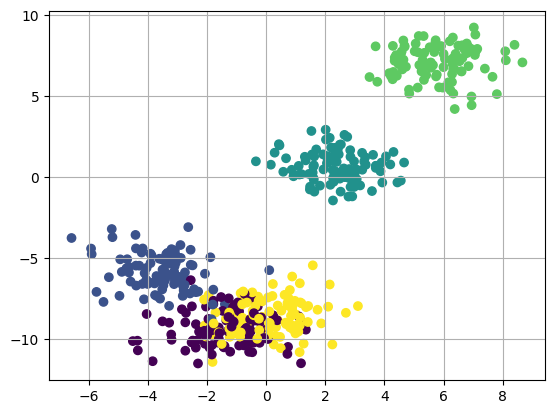

In [ ]:
fig = plt.figure()
plt.grid(True)
plt.scatter(X[:,0],X[:,1],c=y)
plt.show()

In [ ]:
from sklearn.preprocessing import StandardScaler

In [ ]:
scaler = StandardScaler()
X = scaler.fit_transform(X)

In [ ]:
k = 5

clusters = {}
np.random.seed(23)

for idx in range(k):
    center = 2*(2*np.random.random((X.shape[1],))-1)
    points = []
    cluster = {
        'center' : center,
        'points' : []
    }

    clusters[idx] = cluster

clusters

{0: {'center': array([ 0.06919154,  1.78785042,  1.06183904, -0.87041662, -1.11581855]),
  'points': []},
 1: {'center': array([ 0.74488834, -1.33144319, -0.43023013,  0.47220939, -0.35227962]),
  'points': []},
 2: {'center': array([-1.99014048,  1.53612873,  1.53979015, -0.79836124,  0.35832746]),
  'points': []},
 3: {'center': array([ 1.91370766,  1.38037529, -1.73969824, -0.82102214, -0.84826224]),
  'points': []},
 4: {'center': array([ 1.28986536,  0.50473215, -1.55808914, -1.99788476,  1.76866493]),
  'points': []}}

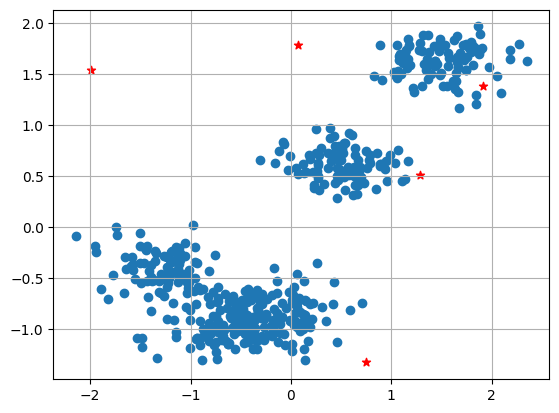

In [ ]:
plt.scatter(X[:,0],X[:,1])
plt.grid(True)
for i in clusters:
    center = clusters[i]['center']
    plt.scatter(center[0],center[1],marker = '*',c = 'red')
plt.show()

In [ ]:
def distance(p1,p2):
    return np.sqrt(np.sum((p1-p2)**2))

In [ ]:
def assign_clusters(X, clusters):
    for idx in range(X.shape[0]):
        dist = []

        curr_x = X[idx]

        for i in range(k):
            dis = distance(curr_x,clusters[i]['center'])
            dist.append(dis)
        curr_cluster = np.argmin(dist)
        clusters[curr_cluster]['points'].append(curr_x)
    return clusters

def update_clusters(X, clusters):
    for i in range(k):
        points = np.array(clusters[i]['points'])
        if points.shape[0] > 0:
            new_center = points.mean(axis =0)
            clusters[i]['center'] = new_center

            clusters[i]['points'] = []
    return clusters

In [ ]:
def pred_cluster(X, clusters):
    pred = []
    for i in range(X.shape[0]):
        dist = []
        for j in range(k):
            dist.append(distance(X[i],clusters[j]['center']))
        pred.append(np.argmin(dist))
    return pred

In [ ]:
# Repeat until convergence or maximum iterations
max_iters = 100

for _ in range(max_iters):
    old_centers = [clusters[i]['center'].copy() for i in range(k)]

    clusters = assign_clusters(X, clusters)
    clusters = update_clusters(X, clusters)

    new_centers = [clusters[i]['center'] for i in range(k)]

    if np.allclose(old_centers, new_centers):
        break

pred = pred_cluster(X, clusters)

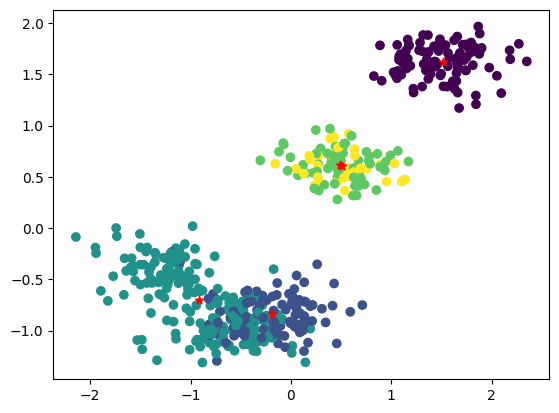

In [ ]:
plt.scatter(X[:,0],X[:,1],c = pred)
for i in clusters:
    center = clusters[i]['center']
    plt.scatter(center[0],center[1],marker = '*',c = 'red')
plt.show()